# Example 16: does GSFit recover a known equilibrium?

FreeGSNKE supplies the reference. Compare exactly three GSFit reconstructions:

1. **Magnetics only (polynomial):** two EFIT coefficients each for p-prime and FF-prime.
2. **Magnetics + isoflux (polynomial):** the same source basis, adding 24 isoflux pairs.
3. **Magnetics + isoflux (spline):** the same measurements, eleven tensioned cubic
   B-spline coefficients per source.

No pressure measurements are fitted. Pressure is compared only as a diagnostic.
Select your GSFit environment and **Restart Kernel and Run All**.
Setup and plotting details are in `helpers.py`; figures and metrics are saved in `plots/`.


In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown
from IPython.display import display

%matplotlib inline

example_dir = Path.cwd()
if not (example_dir / "helpers.py").is_file():
    example_dir = example_dir / "examples" / "example_16__mastu__freegsnke_isoflux"
if not (example_dir / "helpers.py").is_file():
    raise RuntimeError("Open this notebook from its directory or the GSFit repository root.")
sys.path.insert(0, str(example_dir))
from helpers import build_reference
from helpers import compare
from helpers import make_pairs
from helpers import reconstruct
from helpers import save_plots

# Edit this path to your trusted FreeGSNKE checkout (its inputs include pickle files).
freegsnke_root = Path.home() / "github" / "freegsnke"
output_dir = example_dir / "plots"
output_dir.mkdir(exist_ok=True)

## 1. Create a deliberately challenging reference equilibrium

Use the same MAST-U machine and coil-current inputs as Example 02, with
600 kA plasma current and 8 kPa axis pressure, but change the source-profile
shape to **alpha_m = 2, alpha_n = 3**:

`p-prime and FF-prime are proportional to (1 - psi_N**2)**3`.

This sixth-order shape cannot be represented exactly by the baseline's
two-coefficient EFIT polynomials; the tensioned splines have more flexibility.
The reference was deliberately selected after trying several shapes to make
this limitation visible, not as an unbiased performance benchmark. The previous
reference used alpha_m = 1.8, alpha_n = 1.2. No measurements, weights, penalties
or initial guesses were weakened to make the baseline worse.

The main comparison changes both the source basis and the isoflux measurements.
It cannot attribute the improvement to isoflux alone. A magnetics-only spline
control is reported in the README. No experimental database is needed.


In [2]:
alpha_m, alpha_n = 2.0, 3.0
reference = build_reference(freegsnke_root.expanduser().resolve(), alpha_m=alpha_m, alpha_n=alpha_n)
print(f"Reference magnetic axis: R={reference.opt[0][0]:.4f} m, Z={reference.opt[0][1]:.4f} m")

Active coils --> built from pickle file.
Passive structures --> built from pickle file.
Limiter --> built from pickle file.
Wall --> built from pickle file.


Magnetic probes --> built from pickle file.


Resistance (R) and inductance (M) matrices --> built using actives (and passives if present).
Tokamak built.


Forward static solve SUCCESS. Tolerance 1.42e-10 (vs. requested 1.00e-09) reached in 28/100 iterations.


Reference magnetic axis: R=1.0569 m, Z=-0.0000 m


## 2. Simulate two TS-like laser lines

We use **12 flux levels from psi_N = 0.01 to 1.00** on each line:

- **Horizontal:** Z = Z_axis, pairing the inboard and outboard crossings.
- **Vertical:** R = R_axis, pairing the lower and upper crossings.

This gives **24 pairs**. Each pair's sample locations lie on the same line and the
same reference flux surface. Blue marks denote horizontal pairs H1-H12;
orange marks denote vertical pairs V1-V12. Dashed lines show the two idealized
laser chords; they are not magnetic field lines.

This is ideal geometry generated from the known reference, **not a TS forward
model**: there is no temperature/density profile, channel sampling, noise or
pair-finding uncertainty. The lines pass through the *reference* magnetic axis
and remain fixed during reconstruction. Crossings are found outward from the
axis, selecting the first crossing on each side.

In an up-down symmetric equilibrium the horizontal pairs may have little or
zero vertical-shift sensitivity; the vertical pairs avoid relying on those
rows alone. More pairs do not guarantee independent information.

The outermost H12 and V12 pairs lie on the reference separatrix (psi_N = 1).


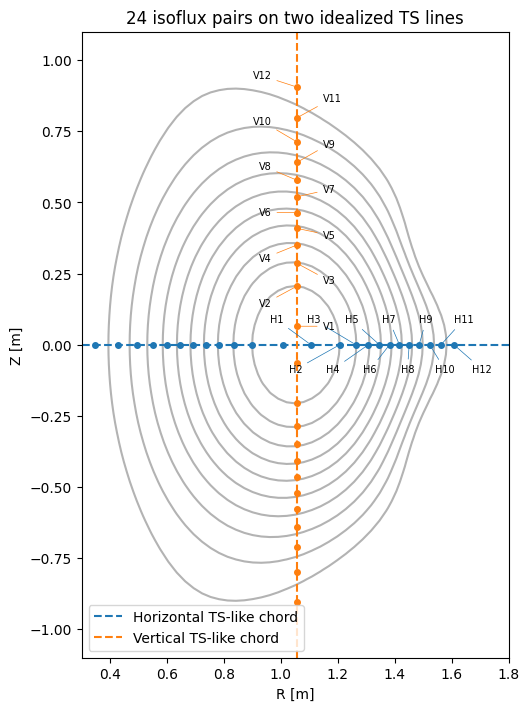

In [3]:
pairs = make_pairs(reference)
assert pairs.shape == (24, 4)
axis_r, axis_z, _ = reference.opt[0]
np.testing.assert_allclose(pairs[:12, 1], axis_z)
np.testing.assert_allclose(pairs[:12, 3], axis_z)
np.testing.assert_allclose(pairs[12:, 0], axis_r)
np.testing.assert_allclose(pairs[12:, 2], axis_r)
assert np.all(pairs[:12, 0] < axis_r) and np.all(pairs[:12, 2] > axis_r)
assert np.all(pairs[12:, 1] < axis_z) and np.all(pairs[12:, 3] > axis_z)
reference_residuals = (
    reference.psiRZ(pairs[:, 0], pairs[:, 1]) - reference.psiRZ(pairs[:, 2], pairs[:, 3])
) * (2 * np.pi)
if not np.all(np.isfinite(reference_residuals)) or np.max(np.abs(reference_residuals)) > 1e-9:
    raise RuntimeError("Reference pairs do not have equal flux within 1e-9 Wb")
# Check that both chords use the intended levels, not merely equal sample location flux.
target_levels = np.tile(np.linspace(0.01, 1.0, 12), 2)
actual_levels = (
    reference.psiRZ(pairs[:, 0], pairs[:, 1]) - reference.opt[0][2]
) / (reference.psi_bndry - reference.opt[0][2])
np.testing.assert_allclose(actual_levels, target_levels, atol=1e-9, rtol=0)

fig, ax = plt.subplots(figsize=(7, 7), constrained_layout=True)
reference_psi_n = (reference.psi() - reference.opt[0][2]) / (reference.psi_bndry - reference.opt[0][2])
ax.contour(reference.R, reference.Z, reference_psi_n, levels=np.linspace(0.1, 0.95, 10), colors="0.7")
ax.axhline(axis_z, color="tab:blue", linestyle="--", label="Horizontal TS-like chord")
ax.axvline(axis_r, color="tab:orange", linestyle="--", label="Vertical TS-like chord")
for i, (r1, z1, r2, z2) in enumerate(pairs):
    horizontal = i < 12
    color = "tab:blue" if horizontal else "tab:orange"
    ax.plot([r1, r2], [z1, z2], "o", color=color, markersize=4)
    if horizontal:
        label_r = np.linspace(pairs[0, 2] - 0.12, pairs[11, 2] + 0.10, 12)[i]
        above = i % 2 == 0
        ax.annotate(f"H{i + 1}", (r2, z2), xytext=(label_r, z2 + (0.07 if above else -0.07)),
                    ha="center", va="bottom" if above else "top", fontsize=7,
                    arrowprops={"arrowstyle": "-", "color": "tab:blue", "linewidth": 0.5})
    else:
        label_z = np.linspace(pairs[12, 3], pairs[-1, 3] + 0.04, 12)[i - 12]
        right = i % 2 == 0
        ax.annotate(f"V{i - 11}", (r2, z2), xytext=(r2 + (0.09 if right else -0.09), label_z),
                    ha="left" if right else "right", va="center", fontsize=7,
                    arrowprops={"arrowstyle": "-", "color": "tab:orange", "linewidth": 0.5})
ax.set(xlabel="R [m]", ylabel="Z [m]", title="24 isoflux pairs on two idealized TS lines", aspect="equal")
ax.set_xlim(0.3, 1.8)
ax.set_ylim(-1.1, 1.1)
ax.legend()
fig.savefig(output_dir / "reference_pairs.png", dpi=150)
plt.show()
plt.close(fig)


## 3. Reconstruct using magnetics only

Synthetic flux loops, Mirnov probes and a plasma-current measurement come from
the reference. All three cases use the same initial current-density seed, centred at
R = 0.8 m and Z = 0 m, with Ip = 500 kA, minor radius 0.5 m and
elongation 2. No solution mixing is applied; delta_z is available
after the first iteration.

This baseline uses `efit_polynomial` with two coefficients each for p-prime and
FF-prime. No pressure or isoflux measurements are supplied. Every reconstruction
must converge; failures stop execution instead of displaying invalid profiles.


In [4]:
magnetics_only = reconstruct(reference, pairs, use_isoflux=False)
magnetics_metrics, magnetics_residuals = compare(reference, magnetics_only, pairs)
print(json.dumps(magnetics_metrics, indent=2, allow_nan=False))

2026-10-29 16:45:11  |  GSFIT  |  diagnostic_and_simulation_base.py:216  |  INFO  |  Loading settings from: "passive_dof_regularisation.json"


2026-10-29 16:45:11  |  GSFIT  |  diagnostic_and_simulation_base.py:216  |  INFO  |  Loading settings from: "sensor_weights_bp_probe.json"


2026-10-29 16:45:11  |  GSFIT  |  diagnostic_and_simulation_base.py:216  |  INFO  |  Loading settings from: "sensor_weights_dialoop.json"


2026-10-29 16:45:11  |  GSFIT  |  diagnostic_and_simulation_base.py:216  |  INFO  |  Loading settings from: "sensor_weights_flux_loops.json"


2026-10-29 16:45:11  |  GSFIT  |  diagnostic_and_simulation_base.py:216  |  INFO  |  Loading settings from: "sensor_weights_isoflux.json"


2026-10-29 16:45:11  |  GSFIT  |  diagnostic_and_simulation_base.py:216  |  INFO  |  Loading settings from: "sensor_weights_rogowski_coils.json"


... (23 outputs left out)

solve_grad_shafranov starting
solve_grad_shafranov: serial setup done; 115.48ms
solve_grad_shafranov: parallel time-slice solve done; 1437.30ms
time= 500.0ms;  solution_found=true;  grad_shafranov_deviation_value=0.000001733193313965;  n_iter=13
equilibrium_post_processor: starting
solve_grad_shafranov: serial finish done; 170.24ms


2026-10-29 16:45:16  |  GSFIT  |  gsfit.py:297                           |  INFO  |  Finished: `gsfit_rs.solve_inverse_problem` time = 1,725.56ms


{
  "convergence_status": 1,
  "iterations": 13,
  "final_delta_z_m": -2.2022598275476523e-05,
  "gs_deviation": 1.7331933139648656e-06,
  "axis_error_m": 0.03229139800679057,
  "max_pair_residual_Wb": 0.06843166103379172,
  "max_pair_residual_over_flux_span": 0.10315336834583833,
  "grid_flux_rms_over_flux_span": 0.01228678582640798,
  "sample_pressure_rms_Pa": 4541.374945322188,
  "sample_pressure_rms_over_axis_pressure": 0.5676718681652736,
  "pprime_rms_over_reference_peak": 1.5114185381464704,
  "ffprime_rms_over_reference_peak": 0.1598069034523255
}


/home/alex.prokopyszyn/GitHub/gsfit/.venv/lib/python3.13/site-packages/freegs4e/jtor.py:64: IntegrationWarning: Extremely bad integrand behavior occurs at some points of the
  integration interval.
  val, _ = quad(self.pprime, pvals[i], 1.0)


### What are the magnetic measurements, and where are they?

These are **noise-free synthetic measurements** from the FreeGSNKE reference,
at positions in its MAST-U-like machine configuration, not an experimental shot.

| Diagnostic | Measurement supplied to GSFit | Symbol in the map |
|---|---|---|
| Flux loops | Poloidal flux in Wb (converted from FreeGSNKE's Wb/(2 pi)) | Blue squares: each toroidal loop appears as a point in the R-Z section. |
| Mirnov probes (poloidal magnetic pickups) | Local field component `B_R cos(angle) + B_Z sin(angle)`, in tesla | Orange triangles; arrows show the measured poloidal direction. Toroidal-oriented probes are excluded. |
| Synthetic plasma-current Rogowski | Reference plasma current: 600 kA | A contour following the limiter, rather than a point sensor. |

Only diagnostics with `include=True` in the active settings are plotted.
Known PF-coil currents are supplied too, but are not additional flux-loop or
Mirnov-probe measurements. No pressure measurements are supplied in any of the three cases.

Only selected points are labelled to avoid crowding; the figure shows all included diagnostics. External
magnetic measurements do not uniquely fix every detail of the internal profile.


Here "Mirnov" refers to the magnetic pickup probes. We supply synthetic field
components in tesla, not raw induced coil voltages or a fluctuation time series.


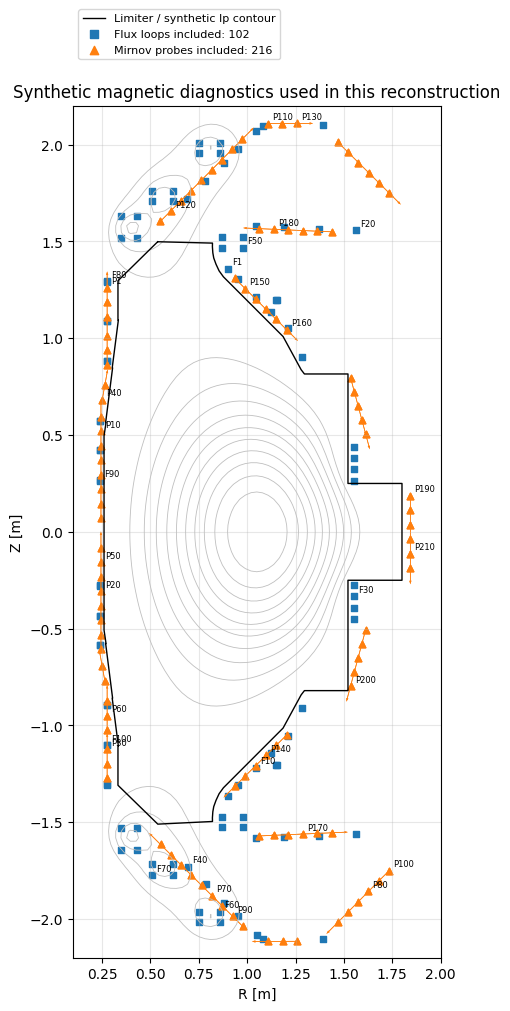

In [5]:
from helpers import plot_sensor_map

plot_sensor_map(reference, magnetics_only, output_dir)

## 4. Add isoflux while retaining EFIT polynomials

Keep the baseline's two polynomial coefficients per source, magnetic measurements,
regularization and initial guess. Add the 24 isoflux pairs, each supplying zero
flux difference with weight 10 in 1/Wb. This isolates the effect of adding isoflux
within the restricted polynomial basis.


In [6]:
isoflux_polynomial = reconstruct(
    reference, pairs, use_isoflux=True, profile_method="efit_polynomial",
)
polynomial_metrics, polynomial_residuals = compare(reference, isoflux_polynomial, pairs)
print(json.dumps(polynomial_metrics, indent=2, allow_nan=False))

2026-10-29 16:45:19  |  GSFIT  |  diagnostic_and_simulation_base.py:216  |  INFO  |  Loading settings from: "passive_dof_regularisation.json"


2026-10-29 16:45:19  |  GSFIT  |  diagnostic_and_simulation_base.py:216  |  INFO  |  Loading settings from: "sensor_weights_bp_probe.json"


2026-10-29 16:45:19  |  GSFIT  |  diagnostic_and_simulation_base.py:216  |  INFO  |  Loading settings from: "sensor_weights_dialoop.json"


2026-10-29 16:45:19  |  GSFIT  |  diagnostic_and_simulation_base.py:216  |  INFO  |  Loading settings from: "sensor_weights_flux_loops.json"


2026-10-29 16:45:19  |  GSFIT  |  diagnostic_and_simulation_base.py:216  |  INFO  |  Loading settings from: "sensor_weights_isoflux.json"


2026-10-29 16:45:19  |  GSFIT  |  diagnostic_and_simulation_base.py:216  |  INFO  |  Loading settings from: "sensor_weights_rogowski_coils.json"


... (21 outputs left out)

2026-10-29 16:45:22  |  GSFIT  |  gsfit.py:352                           |  INFO  |  Finished Greens with plasma;  1,388.21ms


2026-10-29 16:45:22  |  GSFIT  |  gsfit.py:277                           |  INFO  |  About to call: `gsfit_rs.solve_grad_shafranov`


solve_grad_shafranov starting
2026-10-29 16:45:23  |  GSFIT  |  gsfit.py:297                           |  INFO  |  Finished: `gsfit_rs.solve_inverse_problem` time = 1,170.47ms


solve_grad_shafranov: serial setup done; 122.53ms
solve_grad_shafranov: parallel time-slice solve done; 878.38ms
time= 500.0ms;  solution_found=true;  grad_shafranov_deviation_value=0.000004476651840107;  n_iter=8
equilibrium_post_processor: starting
solve_grad_shafranov: serial finish done; 167.91ms
{
  "convergence_status": 1,
  "iterations": 8,
  "final_delta_z_m": -4.093617601856774e-06,
  "gs_deviation": 4.476651840106829e-06,
  "axis_error_m": 0.0049228458961108335,
  "max_pair_residual_Wb": 0.00928512188612829,
  "max_pair_residual_over_flux_span": 0.013996322514849328,
  "grid_flux_rms_over_flux_span": 0.006845672484235082,
  "sample_pressure_rms_Pa": 648.966399664209,
  "sample_pressure_rms_over_axis_pressure": 0.08112079995802614,
  "pprime_rms_over_reference_peak": 0.2204224015582406,
  "ffprime_rms_over_reference_peak": 0.08839752073459471
}


## 5. Retain isoflux and change to tensioned cubic B-splines

Keep the same magnetics and isoflux measurements and weights, but use eleven
spline coefficients each for p-prime and FF-prime:

- Seven interior knots at psi_N = 1/8, 2/8, ..., 7/8; tension 1 on every interval.
- Coefficient second-difference penalty, ridge damping factor 0.01 and
  last-coefficient penalty factor 100.
- Penalty scales: 1e-5 for p-prime and 1 for FF-prime.

These are exploratory coefficient penalties, not exact derivative regularization.
Changing the basis also changes effective regularization. The comparison with
case 2 tests profile flexibility at fixed measurements, not isoflux alone.
No pressure measurements are added.


In [7]:
from gsfit_rs.imas import equilibrium_paths as ep

with_isoflux = reconstruct(
    reference, pairs, use_isoflux=True, profile_method="tensioned_cubic_b_spline",
    spline_n_interior=7,
)
isoflux_metrics, isoflux_residuals = compare(reference, with_isoflux, pairs)
for controller, n_dof, n_pairs in (
    (magnetics_only, 2, 0), (isoflux_polynomial, 2, 24), (with_isoflux, 11, 24),
):
    assert len(controller.pressure_sensors.keys()) == 0
    assert len(controller.isoflux.keys()) == n_pairs
    assert controller.plasma.get(ep.time_slice[0].source_functions.p_prime.coefficients).size == n_dof
    assert controller.plasma.get(ep.time_slice[0].source_functions.ff_prime.coefficients).size == n_dof
print(json.dumps(isoflux_metrics, indent=2, allow_nan=False))

2026-10-29 16:45:23  |  GSFIT  |  diagnostic_and_simulation_base.py:216  |  INFO  |  Loading settings from: "passive_dof_regularisation.json"


2026-10-29 16:45:23  |  GSFIT  |  diagnostic_and_simulation_base.py:216  |  INFO  |  Loading settings from: "sensor_weights_bp_probe.json"


2026-10-29 16:45:23  |  GSFIT  |  diagnostic_and_simulation_base.py:216  |  INFO  |  Loading settings from: "sensor_weights_dialoop.json"


2026-10-29 16:45:23  |  GSFIT  |  diagnostic_and_simulation_base.py:216  |  INFO  |  Loading settings from: "sensor_weights_flux_loops.json"


2026-10-29 16:45:23  |  GSFIT  |  diagnostic_and_simulation_base.py:216  |  INFO  |  Loading settings from: "sensor_weights_isoflux.json"


2026-10-29 16:45:23  |  GSFIT  |  diagnostic_and_simulation_base.py:216  |  INFO  |  Loading settings from: "sensor_weights_rogowski_coils.json"


... (22 outputs left out)

2026-10-29 16:45:26  |  GSFIT  |  gsfit.py:277                           |  INFO  |  About to call: `gsfit_rs.solve_grad_shafranov`


solve_grad_shafranov starting
2026-10-29 16:45:42  |  GSFIT  |  gsfit.py:297                           |  INFO  |  Finished: `gsfit_rs.solve_inverse_problem` time = 15,683.86ms


solve_grad_shafranov: serial setup done; 129.94ms
solve_grad_shafranov: parallel time-slice solve done; 15355.92ms
time= 500.0ms;  solution_found=true;  grad_shafranov_deviation_value=0.000002818948150720;  n_iter=9
equilibrium_post_processor: starting
solve_grad_shafranov: serial finish done; 195.89ms


{
  "convergence_status": 1,
  "iterations": 9,
  "final_delta_z_m": -1.0909221012212465e-06,
  "gs_deviation": 2.8189481507201065e-06,
  "axis_error_m": 0.000256516562803248,
  "max_pair_residual_Wb": 0.00043718573825696216,
  "max_pair_residual_over_flux_span": 0.0006590104757459939,
  "grid_flux_rms_over_flux_span": 0.003611385684528748,
  "sample_pressure_rms_Pa": 498.7906970774191,
  "sample_pressure_rms_over_axis_pressure": 0.0623488371346774,
  "pprime_rms_over_reference_peak": 0.12382050201802426,
  "ffprime_rms_over_reference_peak": 0.11284065709239091
}


## 6. Compare the three results

Each panel compares blue solid reference contours with orange dashed GSFit
contours. Thick blue and thick dashed orange contours explicitly mark
psi_N = 1 (the LCFS level, including separatrix branches) for each equilibrium.
All three cases appear in the contour, residual and profile plots.
Pair residuals are evaluated on each returned flux grid.

The pressure RMS is evaluated at all 48 sample locations using linear interpolation
of each returned pressure grid. It is reported in Pa and normalized by
the **reference axis pressure (8000 Pa)**, not pointwise pressure, which
is zero at the separatrix. This metric differs from the previous
pointwise-relative RMS and must not be compared numerically with it.
No pressure measurements are fitted. These pressure values are diagnostic
comparisons at the reference-generated pair locations, not an independent
experimental validation set.
All figures and numerical results are saved in `plots/`.

Source-profile RMS compares values at the stored psi_N grid points,
uniformly weighted in psi_N, divided by the peak absolute reference
value. It is not a pointwise-relative error or a magnetic measurement residual.


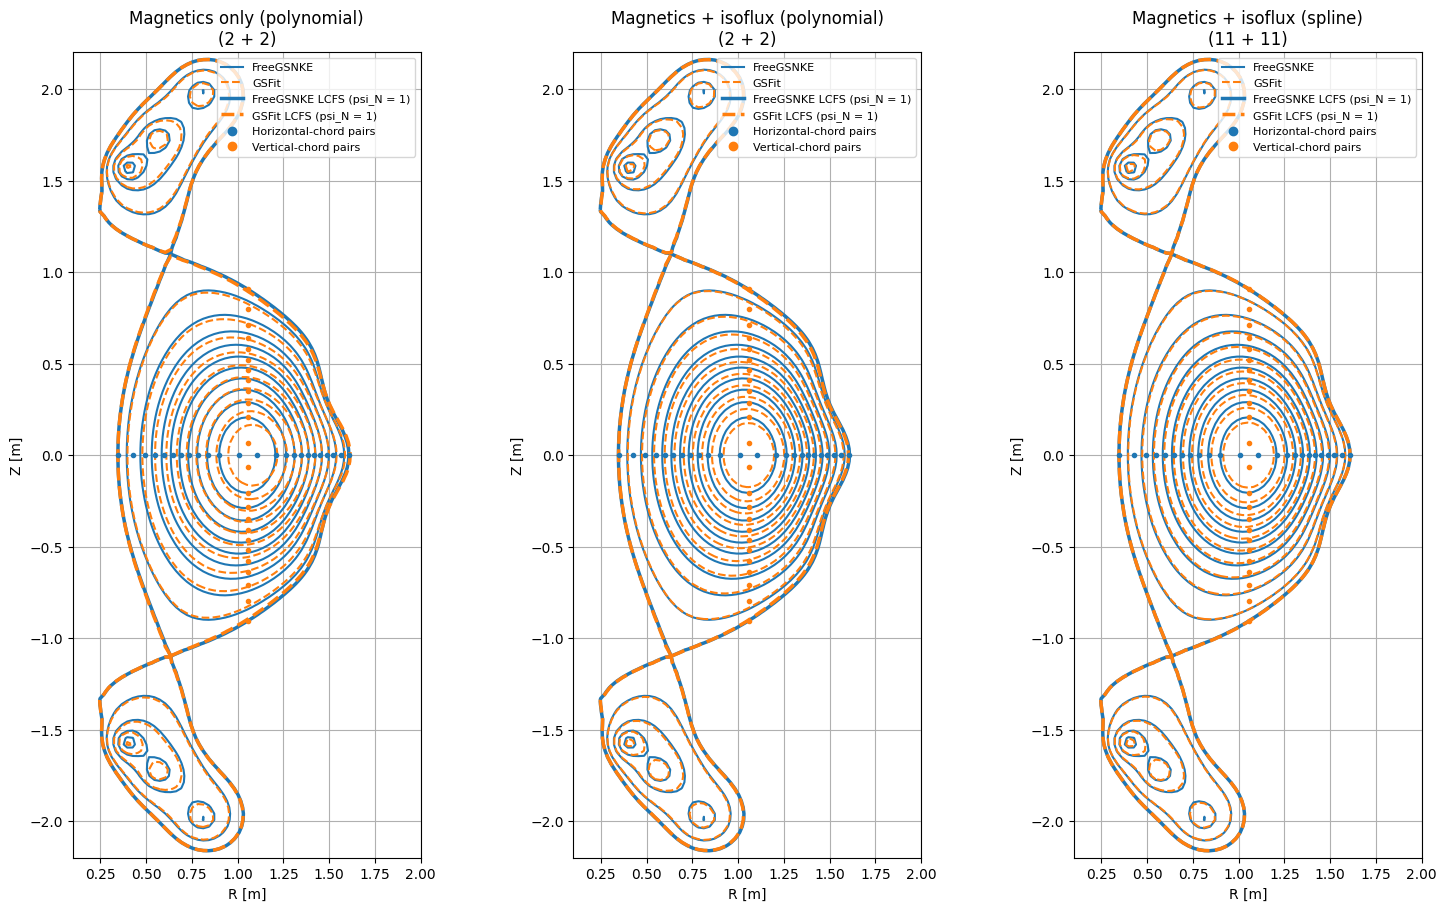

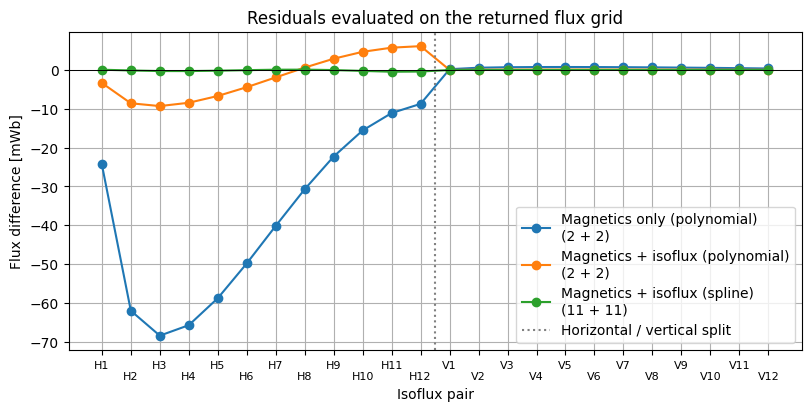

| Quantity | Magnetics only (polynomial) | Magnetics + isoflux (polynomial) | Magnetics + isoflux (spline) |
|---|---:|---:|---:|
| Iterations | 13 | 8 | 9 |
| p-prime RMS / reference peak [%] | 151.14 | 22.04 | 12.38 |
| FF-prime RMS / reference peak [%] | 15.98 | 8.84 | 11.28 |
| Pressure difference RMS at sample locations [Pa] | 4541.37 | 648.97 | 498.79 |
| Pressure RMS / reference axis pressure [%] | 56.767 | 8.112 | 6.235 |
| Magnetic-axis error [mm] | 32.291 | 4.923 | 0.257 |
| Maximum pair residual [mWb] | 68.43166 | 9.28512 | 0.43719 |
| Flux-grid RMS / flux span [%] | 1.2287 | 0.6846 | 0.3611 |
| Final delta_z [mm] | -0.02202 | -0.00409 | -0.00109 |


In [8]:
profile_controllers = [magnetics_only, isoflux_polynomial, with_isoflux]
profile_labels = [
    "Magnetics only (polynomial)",
    "Magnetics + isoflux (polynomial)",
    "Magnetics + isoflux (spline)",
]
# Numbers are p-prime + FF-prime degrees of freedom, not total fit parameters.
comparison_labels = [
    "Magnetics only (polynomial)\n(2 + 2)",
    "Magnetics + isoflux (polynomial)\n(2 + 2)",
    "Magnetics + isoflux (spline)\n(11 + 11)",
]
comparison_residuals = [magnetics_residuals, polynomial_residuals, isoflux_residuals]
metrics = {
    "magnetics_only": magnetics_metrics,
    "magnetics_isoflux_polynomial": polynomial_metrics,
    "magnetics_and_isoflux_spline": isoflux_metrics,
}
(output_dir / "metrics.json").write_text(json.dumps(metrics, indent=2, allow_nan=False) + "\n")
assert all(np.isfinite(value) for result in metrics.values() for value in result.values())
# Broad regression bounds, not exact floating-point or iteration-count targets.
for controller, result in zip(profile_controllers, metrics.values(), strict=True):
    numerics = controller.settings["GSFIT_code_settings.json"]["numerics"]
    assert result["convergence_status"] == 1, (controller.run_name, result)
    assert 0 <= result["gs_deviation"] <= numerics["grad_shafranov_deviation_tolerance"], result
    assert 0 <= result["iterations"] <= numerics["n_iter_max"], result
for result in (polynomial_metrics, isoflux_metrics):
    assert result["max_pair_residual_Wb"] < magnetics_metrics["max_pair_residual_Wb"], result
assert isoflux_metrics["axis_error_m"] < 2e-3, isoflux_metrics
assert isoflux_metrics["max_pair_residual_Wb"] < 1e-3, isoflux_metrics
assert isoflux_metrics["sample_pressure_rms_Pa"] < 1000.0, isoflux_metrics
save_plots(
    reference, profile_controllers, pairs, comparison_residuals,
    comparison_labels, output_dir, show=True,
)

rows = [
    ("Iterations", "iterations", 1.0, ".0f"),
    ("p-prime RMS / reference peak [%]", "pprime_rms_over_reference_peak", 100.0, ".2f"),
    ("FF-prime RMS / reference peak [%]", "ffprime_rms_over_reference_peak", 100.0, ".2f"),
    ("Pressure difference RMS at sample locations [Pa]", "sample_pressure_rms_Pa", 1.0, ".2f"),
    ("Pressure RMS / reference axis pressure [%]", "sample_pressure_rms_over_axis_pressure", 100.0, ".3f"),
    ("Magnetic-axis error [mm]", "axis_error_m", 1e3, ".3f"),
    ("Maximum pair residual [mWb]", "max_pair_residual_Wb", 1e3, ".5f"),
    ("Flux-grid RMS / flux span [%]", "grid_flux_rms_over_flux_span", 100.0, ".4f"),
    ("Final delta_z [mm]", "final_delta_z_m", 1e3, ".5f"),
]
table = "| Quantity | " + " | ".join(profile_labels) + " |\n"
table += "|---|" + "---:|" * len(metrics) + "\n"
for label, key, scale, precision in rows:
    values = [format(result[key] * scale, precision) for result in metrics.values()]
    table += f"| {label} | " + " | ".join(values) + " |\n"
display(Markdown(table))

## 7. Compare p-prime and FF-prime against sqrt(psi_N)

The left plot shows **p-prime = dp/dpsi**; the right shows
**FF-prime = F dF/dpsi**, where F = R B_phi. The horizontal axis is
sqrt(psi_N), from the magnetic axis (0) to the plasma boundary (1).
Changing the horizontal axis does **not** change the derivative definitions:
these are not derivatives with respect to sqrt(psi_N).

FreeGSNKE differentiates with respect to flux in Wb/(2 pi); GSFit uses Wb.
The FreeGSNKE reference derivatives are therefore divided by **2 pi** before
comparison. This conversion is essential.

All three converged reconstructions are overlaid against the reference.
No pressure measurements constrain these profiles. Isoflux constrains geometry;
p-prime and FF-prime can still compensate each other in the toroidal current.
The more flexible case still needs regularization.


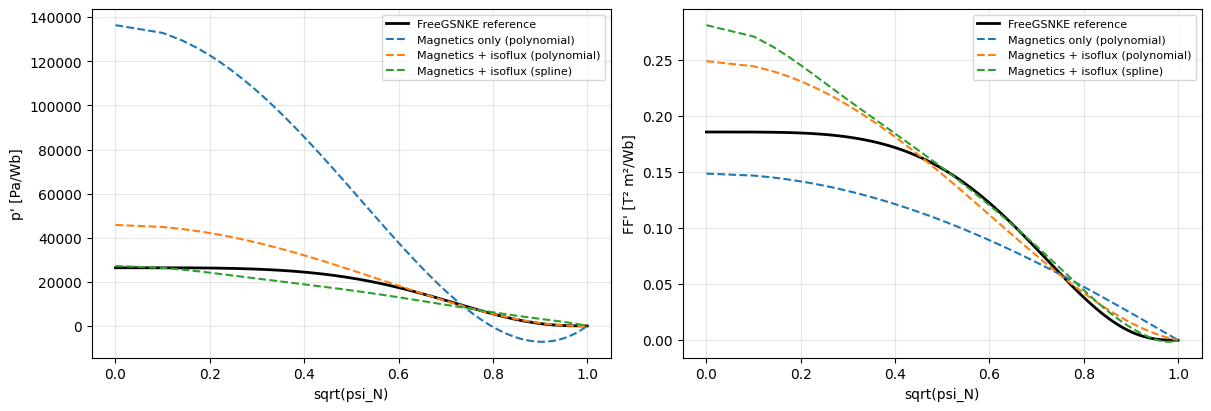

In [9]:
from helpers import plot_source_profiles

plot_source_profiles(reference, profile_controllers, profile_labels, output_dir)

## 8. Compare pressure across the midplane

All curves use the **same geometric plane Z = 0 m**, rather than each
equilibrium's magnetic-axis height. Both inboard and outboard profiles are shown.

GSFit pressure is linearly interpolated from its stored two-dimensional pressure
grid, including its plasma mask. Reference pressure is evaluated at reference
midplane flux. Each curve stops at its own two LCFS crossings (psi_N = 1),
located by linear interpolation of sampled midplane flux. No vacuum
pressure tails are plotted. Pressure is in
kPa; **no 2 pi conversion applies to pressure itself**.

None of the cases fits pressure. This plot checks pressure recovery from
magnetics and geometry alone.


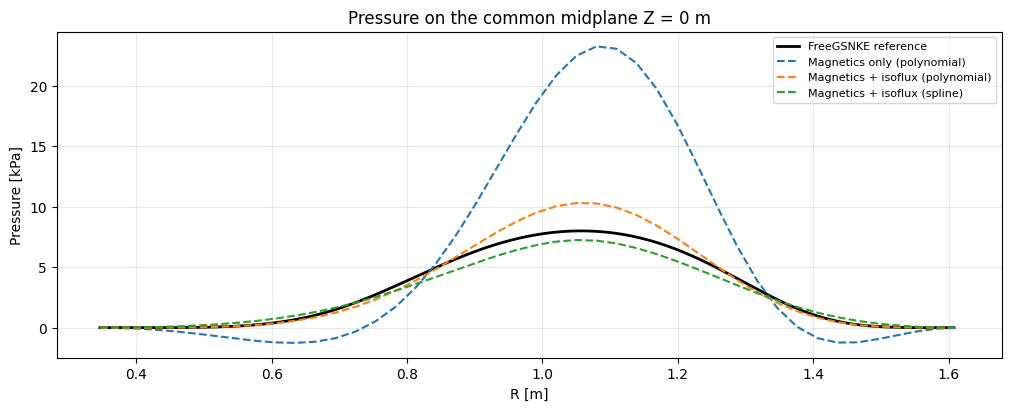

In [10]:
from helpers import plot_midplane_pressure

plot_midplane_pressure(reference, profile_controllers, profile_labels, output_dir)